In [9]:
import mdtraj as md
from pathlib import Path
import json
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
import seaborn as sns

import sys
sys.path.append('..')
from src import visualisation as vis

In [10]:
# Loading data
system_contact_dir = '../data/contact_definition/pipeline/sh3-prm'
system = {
    'pae': np.load(system_contact_dir+'/pae.npy'),
    'pinc': np.load(system_contact_dir+'/pinc.npy'),
    'min_dist': np.load(system_contact_dir+'/min_dist.npy'),
    'avg_plddt': np.load(system_contact_dir+'/avg_plddt.npy'),
    'scm': np.load(system_contact_dir+'/scm.npy'),
    'contacts': np.load(system_contact_dir+'/contacts.npy'),
}
acceptor_chainid = 'A'
donor_chainid = 'B'

Text(366.88541666666663, 0.5, 'Acceptor residue')

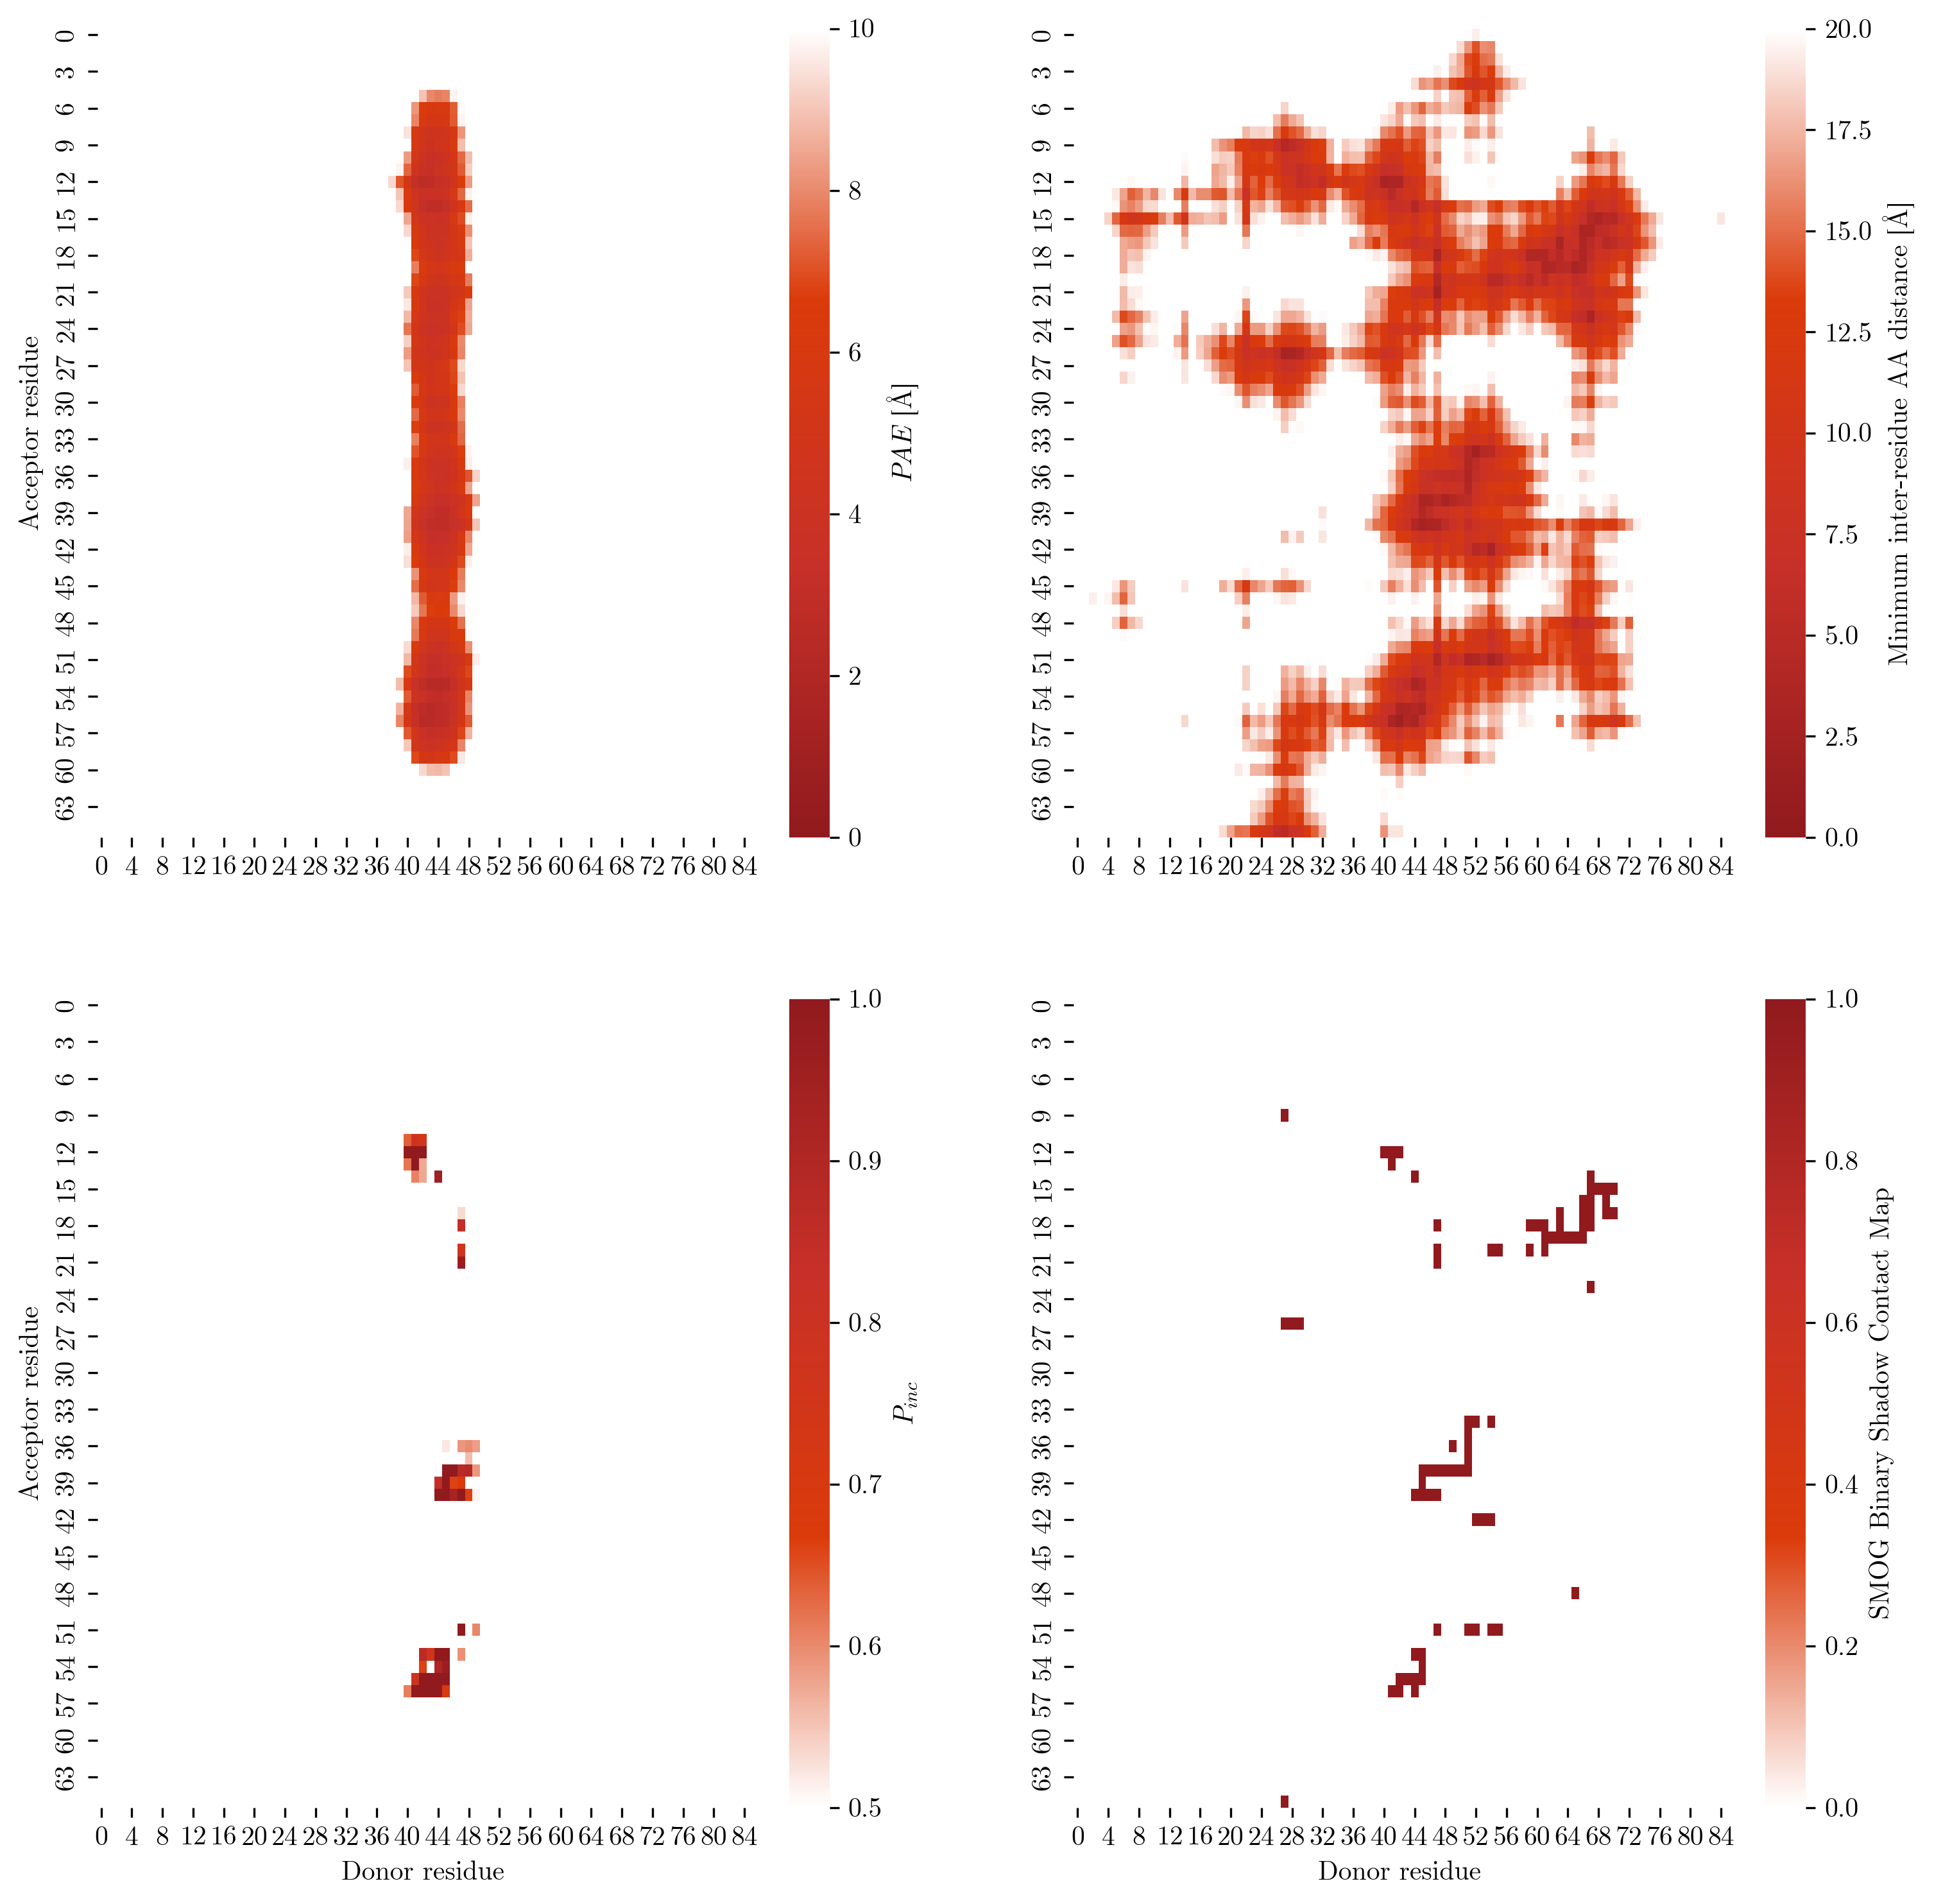

In [ ]:
fig, axes = plt.subplots(2,2, figsize=(12,12))
plt.subplots_adjust(wspace=0.5, hspace=0.5)

sns.heatmap(
    system['pae'], vmin=0, vmax=10,
    cmap=vis.cmap.red_cmap.reversed(),
    cbar_kws=dict(label='$PAE$ [Å]'), ax=axes[0,0]
)


sns.heatmap(
    system['pinc'], vmin=0.5, vmax=1,
    cmap=vis.cmap.red_cmap,
    cbar_kws=dict(label='$P_{inc}$'), ax=axes[1,0]
)

sns.heatmap(
    system['min_dist'], vmin=0, vmax=20,
    cmap=vis.cmap.red_cmap.reversed(),
    cbar_kws=dict(label='Minimum inter-residue AA distance [Å]'), ax=axes[0,1]
)

sns.heatmap(
    system['scm'], vmin=0, vmax=1,
    cmap=vis.cmap.red_cmap,
    cbar_kws=dict(label='SMOG Binary Shadow Contact Map'), ax=axes[1,1]
)

axes[1,0].set_xlabel('Donor residue')
axes[1,1].set_xlabel('Donor residue')
axes[0,0].set_ylabel('Acceptor residue')
axes[1,0].set_ylabel('Acceptor residue')

Text(0, 0.5, 'Predicted alignment error, PAE [Å]')

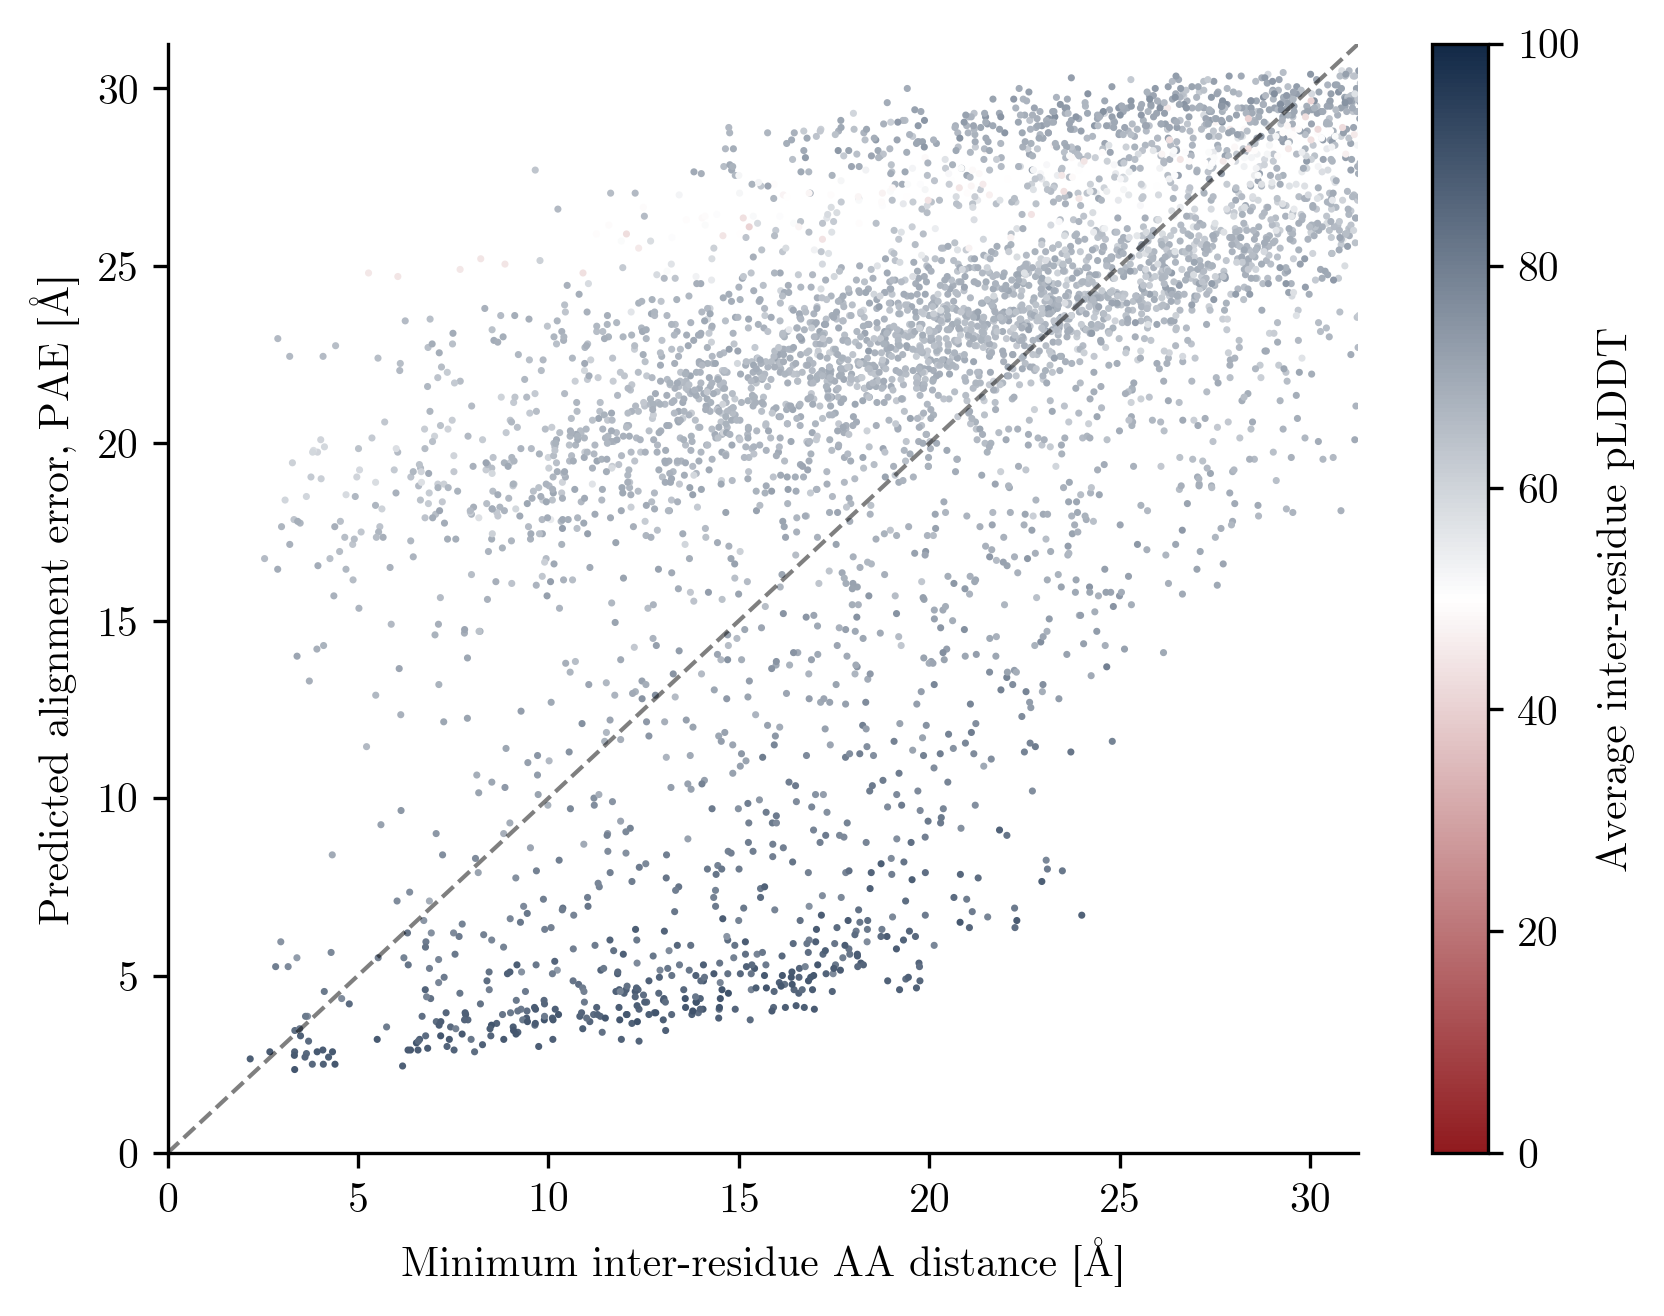

In [12]:
plt.scatter(
    system['min_dist'],
    system['pae'],
    s=0.5,
    c=system['avg_plddt'], vmin=0, vmax=100,
    cmap=vis.cmap.diverging_cmap.reversed(),
)
plt.colorbar(label='Average inter-residue pLDDT')
plt.plot([0,100],[0,100], alpha=0.5, c='k', linestyle='dashed')
plt.xlim(0,system['pae'].max())
plt.ylim(0,system['pae'].max())
plt.xlabel("Minimum inter-residue AA distance [Å]")
plt.ylabel("Predicted alignment error, PAE [Å]")

In [13]:
contact_defs = np.array([
    system['pae'] < 5,
    system['pinc'] > 0.5,
    system['min_dist'] < 10,
    system['scm']
])

In [14]:
slim_pairs = np.argwhere(contact_defs[0] & contact_defs[1] & contact_defs[3]) + 1
print("sel", end=' ')
print(f"/{acceptor_chainid}:"+",".join(np.unique(slim_pairs[:,0].astype(str))), end=' ')
print("|", end=' ')
print(f"/{donor_chainid}:"+",".join(np.unique(slim_pairs[:,1].astype(str))))

sel /A:13,14,15,39,40,41,52,54,55,56,57 | /B:42,43,44,45,46,47,48


In [15]:
sel /A:13,14,15,37,39,40,41,52,54,55,56,57 | /B:41,42,43,44,45,46,47,48,49,50
sel /A:13,14,15,   39,40,41,52,54,55,56,57 | /B:   42,43,44,45,46,47,48

SyntaxError: illegal target for annotation (2065887378.py, line 1)

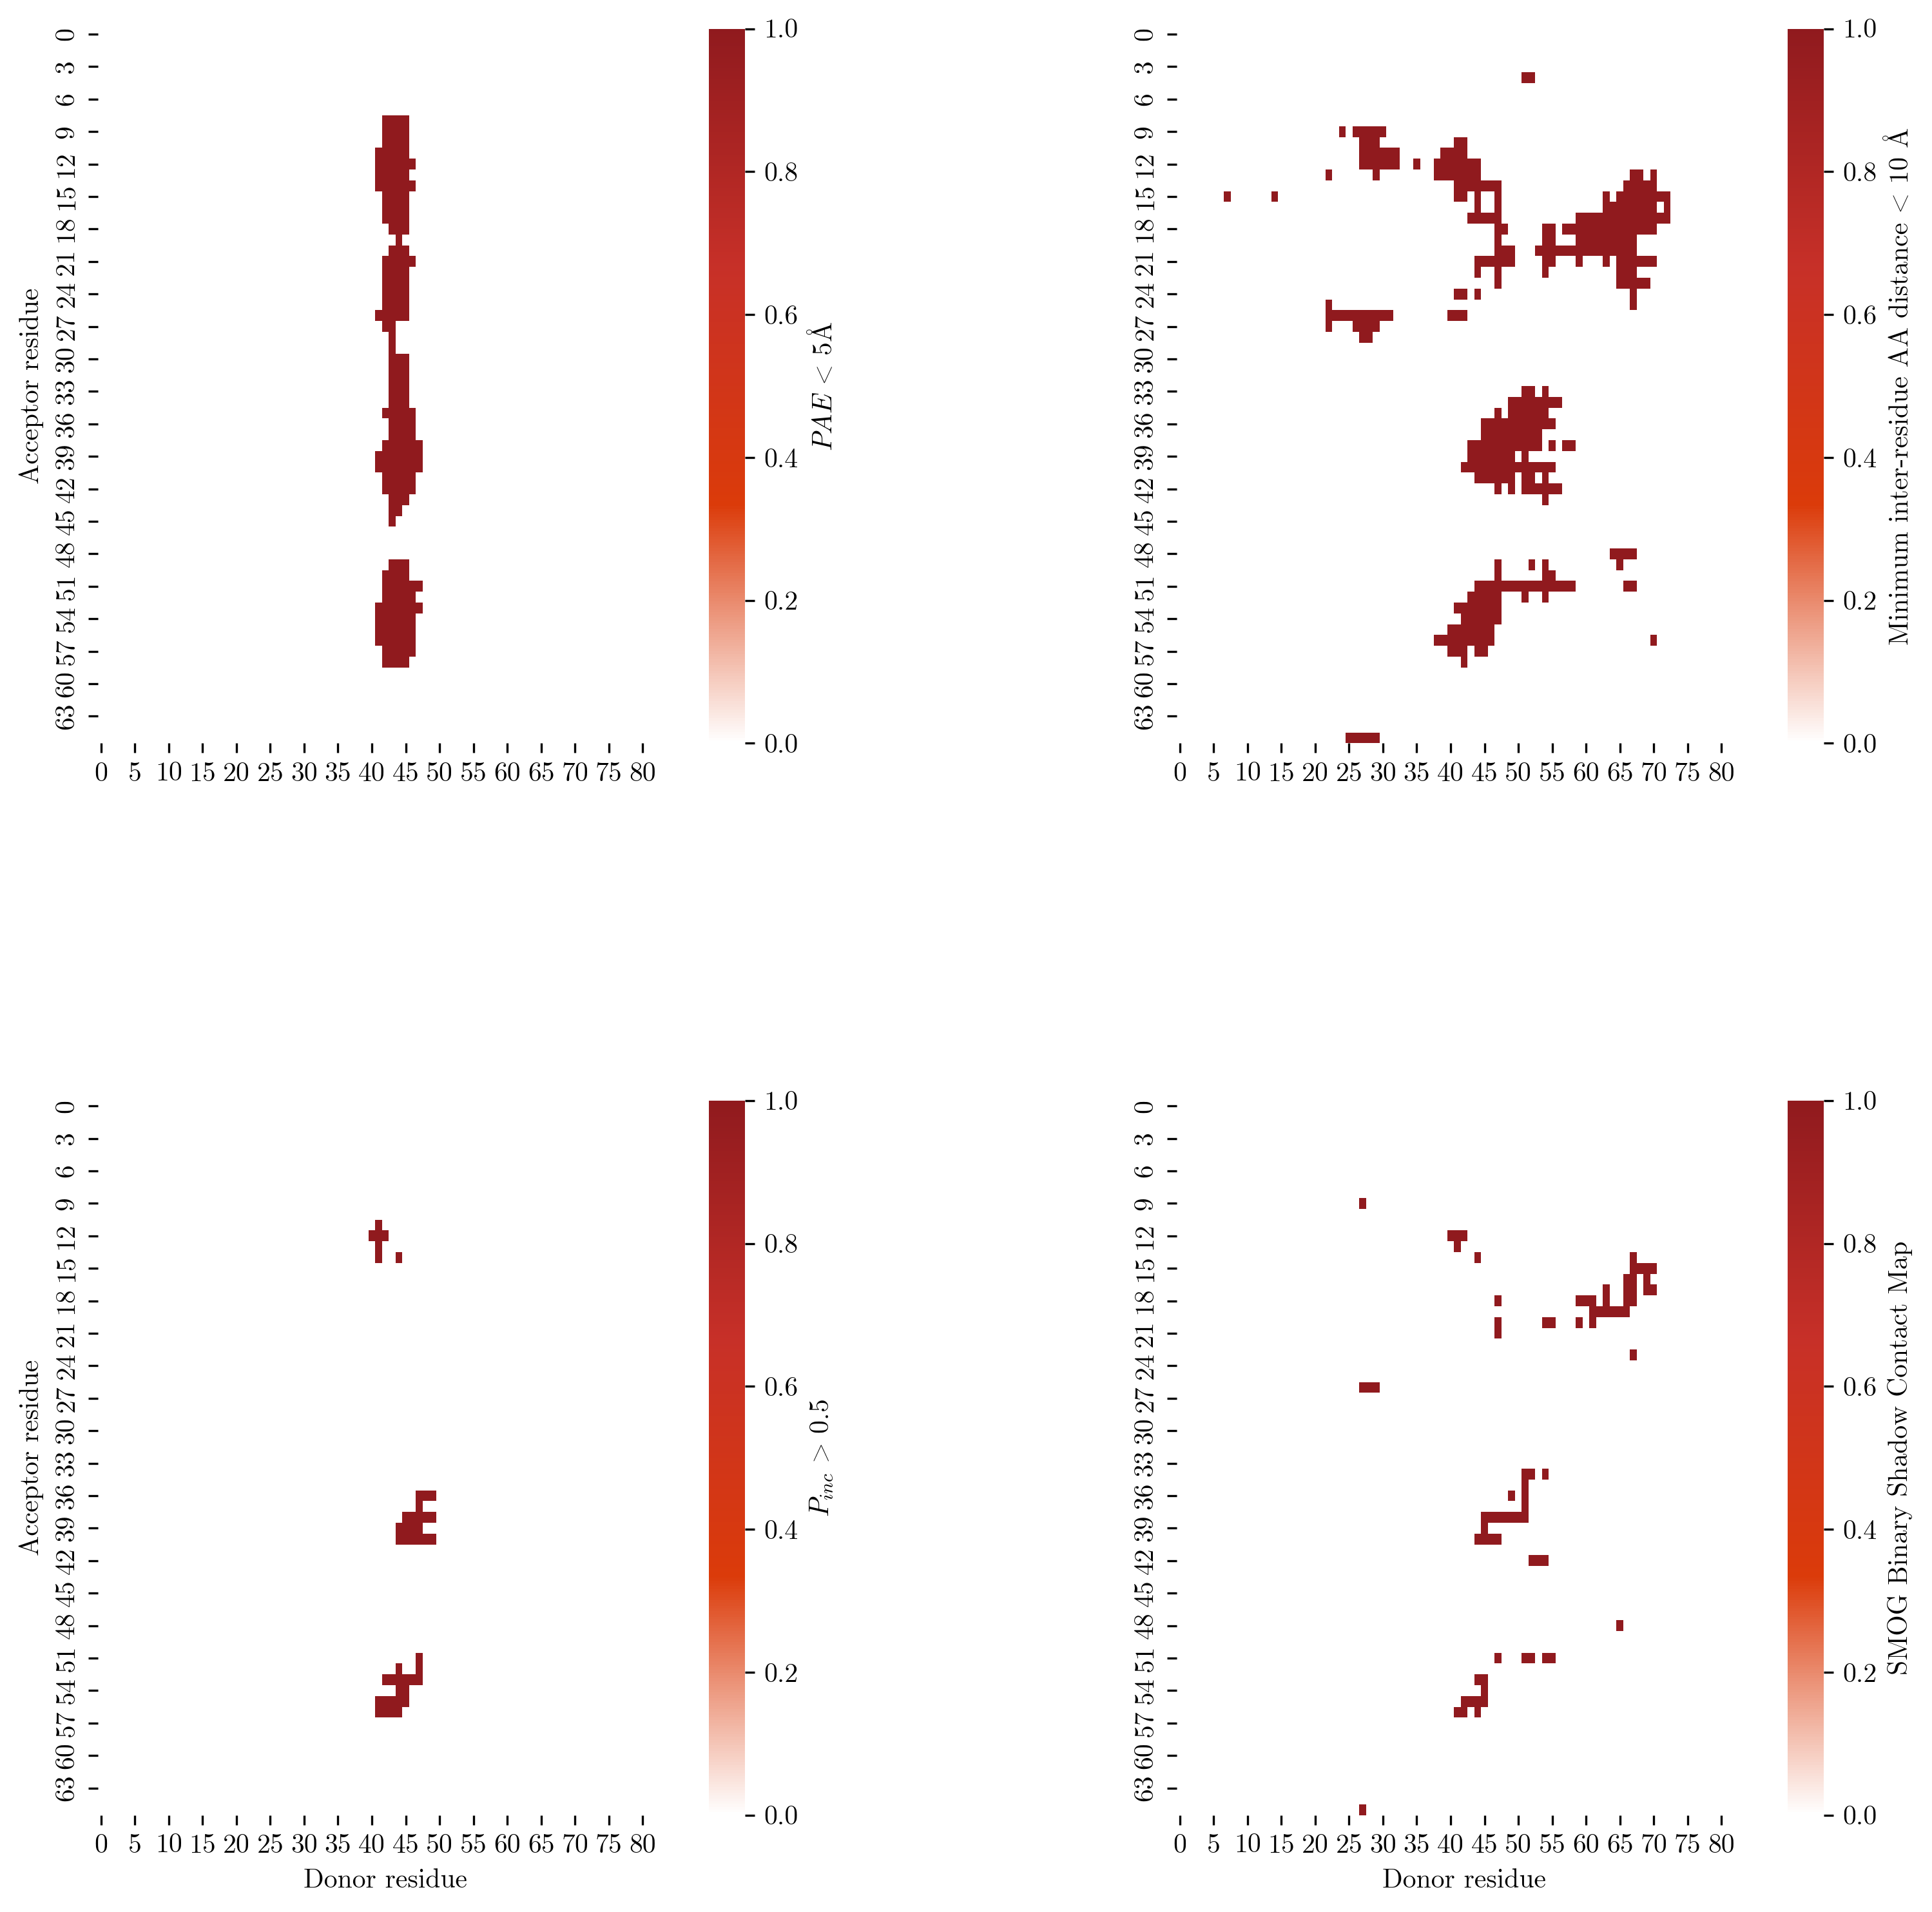

<Axes: >

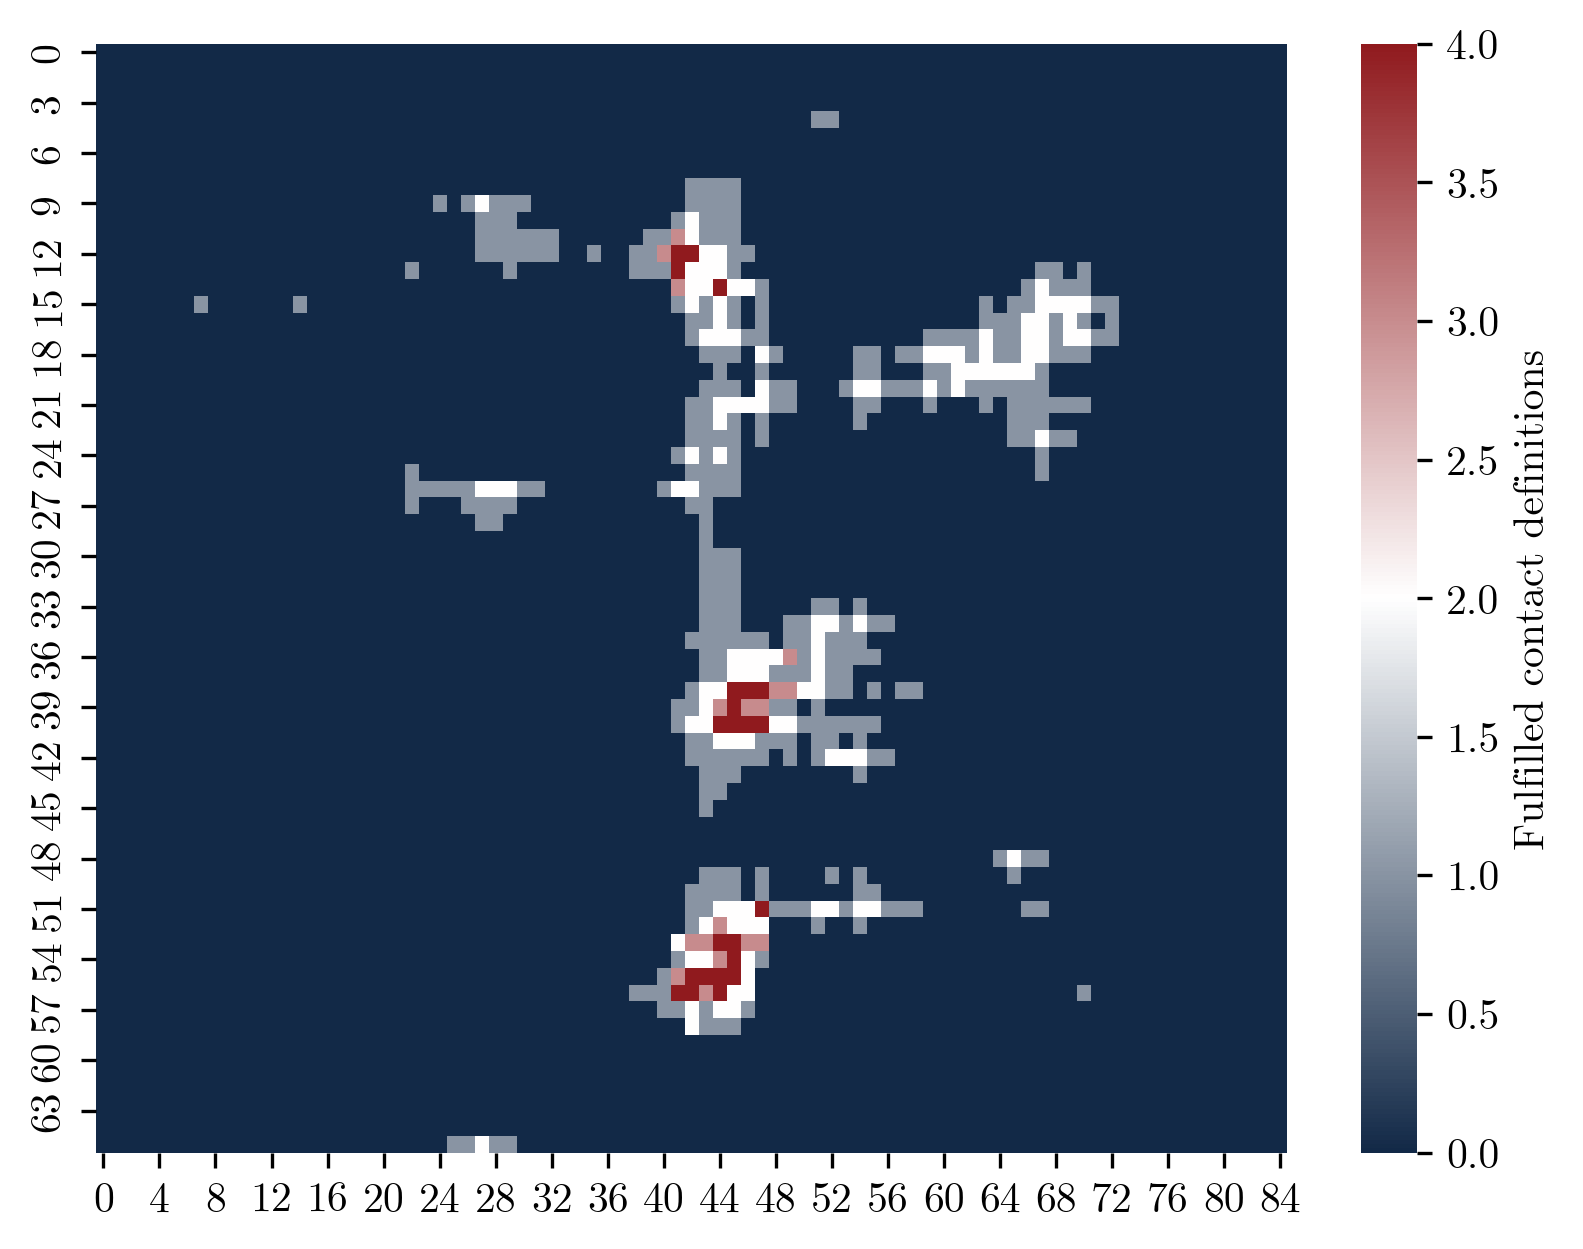

In [ ]:
fig, axes = plt.subplots(2,2, figsize=(12,12))
plt.subplots_adjust(wspace=0.5, hspace=0.5)

sns.heatmap(
    contact_defs[0],
    cmap=vis.cmap.red_cmap,
    cbar_kws=dict(label='$PAE$ < 5Å'), ax=axes[0,0]
)


sns.heatmap(
    contact_defs[1],
    cmap=vis.cmap.red_cmap,
    cbar_kws=dict(label='$P_{inc}$ > 0.5'), ax=axes[1,0]
)

sns.heatmap(
    contact_defs[2],
    cmap=vis.cmap.red_cmap,
    cbar_kws=dict(label='Minimum inter-residue AA distance < 10 Å'), ax=axes[0,1]
)

sns.heatmap(
    contact_defs[3],
    cmap=vis.cmap.red_cmap,
    cbar_kws=dict(label='SMOG Binary Shadow Contact Map'), ax=axes[1,1]
)

axes[1,0].set_xlabel('Donor residue')
axes[1,1].set_xlabel('Donor residue')
axes[0,0].set_ylabel('Acceptor residue')
axes[1,0].set_ylabel('Acceptor residue')

plt.show()

sns.heatmap(
    contact_defs.sum(axis=0),
    cmap=vis.cmap.diverging_cmap,
    cbar_kws=dict(label='Fulfilled contact definitions')
)

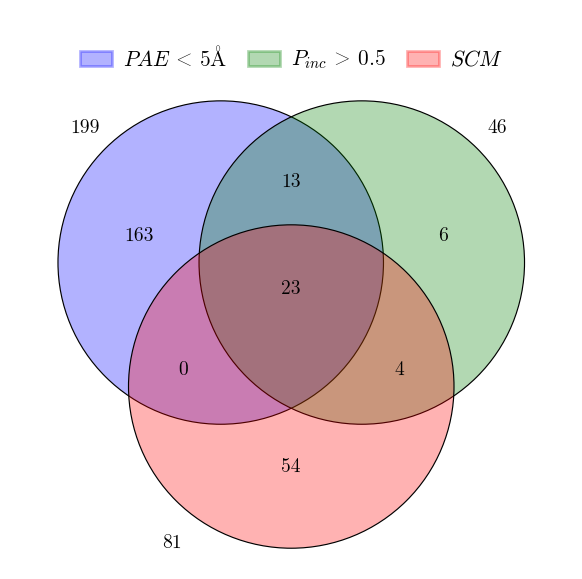

In [ ]:
from venny4py.venny4py import venny4py
sets = {
    '$PAE$ < 5Å': set(list(map(lambda p: str(p), np.argwhere(contact_defs[0])))),
    '$P_{inc}$ > 0.5': set(list(map(lambda p: str(p), np.argwhere(contact_defs[1])))),
#    '$MinDist$ < 10Å': set(list(map(lambda p: str(p), np.argwhere(contact_defs[2])))),
    '$SCM$': set(list(map(lambda p: str(p), np.argwhere(contact_defs[3]))))
}
    
venny4py(sets=sets)
